In [1]:
import matplotlib.pyplot as plt
import numpy as np
import glob
from astropy.io import fits 
import derryck

In [2]:
file_path = 'SeamusDerryck/'
darks_10s = sorted(glob.glob(file_path + 'Darks1*.fit'))
darks_30s = sorted(glob.glob(file_path + 'Darks3*.fit'))
Peg_28 = sorted(glob.glob(file_path + '28 Peg*.fit'))
Peg_pi = sorted(glob.glob(file_path + 'Pi Peg*.fit'))
HD_216354 = sorted(glob.glob(file_path + 'HD 216354*.fit'))
SA_113274_1 = sorted(glob.glob(file_path + 'SA 113274-*.fit'))
SA_113274_2 = sorted(glob.glob(file_path + 'SA 113274 2nd*.fit'))
HD_199280 = sorted(glob.glob(file_path + 'HD 199280*.fit'))
twilights = sorted(glob.glob(file_path + 'twilight*.fit'))
bias = sorted(glob.glob(file_path + 'Bias*.fit'))

In [3]:
darks_10s_data, darks_10s_headers = derryck.open_all_fits(darks_10s)
darks_30s_data, darks_30s_headers =  derryck.open_all_fits(darks_30s)
Peg_28_data, Peg_28_headers = derryck.open_all_fits(Peg_28)
Peg_pi_data, Peg_pi_headers =  derryck.open_all_fits(Peg_pi)
HD_216354_data, HD_216354_headers = derryck.open_all_fits(HD_216354)
HD_199280_data, HD_199280_headers =  derryck.open_all_fits(HD_199280)
SA_113274_1_data, SA_113274_1_headers = derryck.open_all_fits(SA_113274_1)
SA_113274_2_data, SA_113274_2_headers =  derryck.open_all_fits(SA_113274_2)
twilights_data, twilights_headers = derryck.open_all_fits(twilights)
bias_data, bias_headers =  derryck.open_all_fits(bias)

In [4]:
darks_10s_data_corrected = derryck.mass_sixteen_to_twelve_correction(darks_10s_data)
darks_30s_data_corrected = derryck.mass_sixteen_to_twelve_correction(darks_30s_data)
Peg_28_data_corrected = derryck.mass_sixteen_to_twelve_correction(Peg_28_data)
Peg_pi_data_corrected = derryck.mass_sixteen_to_twelve_correction(Peg_pi_data)
HD_199280_data_corrected = derryck.mass_sixteen_to_twelve_correction(HD_199280_data)
HD_216354_data_corrected = derryck.mass_sixteen_to_twelve_correction(HD_216354_data)
SA_113274_1_data_corrected = derryck.mass_sixteen_to_twelve_correction(SA_113274_1_data)
SA_113274_2_data_corrected = derryck.mass_sixteen_to_twelve_correction(SA_113274_2_data)
twilights_data_corrected = derryck.mass_sixteen_to_twelve_correction(twilights_data)
bias_data_corrected = derryck.mass_sixteen_to_twelve_correction(bias_data)

In [5]:
bias_mean = np.mean(bias_data_corrected,axis=0)
bias_median = np.median(bias_mean)
bias_median
print(np.mean(bias_data_corrected), np.sqrt(np.mean(bias_data_corrected)),bias_median)

153.61657170026987 12.394215251490103 153.65


In [9]:
dark_10s_mean = np.mean(darks_10s_data_corrected,axis=0)
dark_30s_mean = np.mean(darks_30s_data_corrected,axis=0)
print(np.mean(darks_10s_data_corrected), np.sqrt(np.mean(darks_10s_data_corrected)))
print(np.mean(darks_30s_data_corrected), np.sqrt(np.mean(darks_30s_data_corrected)))

154.19062262172383 12.417351675044234
154.94980143833263 12.447883411983446


In [6]:
twilights_data_reduced = [
    (image - bias_mean) / np.median(image) for image in twilights_data_corrected[24:74, :, :]
]

In [7]:
flat_median = np.median(twilights_data_reduced, axis=0)
print(np.mean(flat_median), np.sqrt(np.mean(flat_median)))

0.6624871517529461 0.8139331371512933


-0.01025896866236967


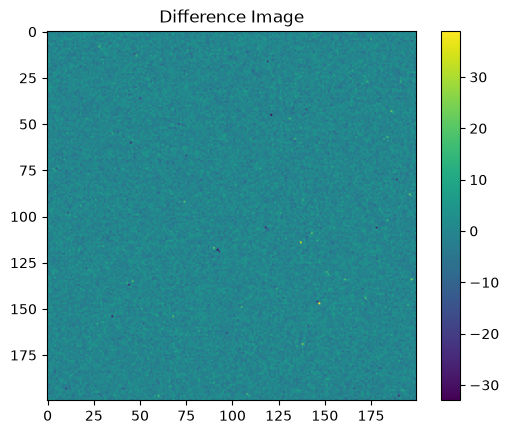

In [44]:
difference_image = bias_data_corrected[9] - bias_data_corrected[14]
plt.imshow(difference_image[1700:1900,2200:2400])
plt.colorbar()
plt.title('Difference Image')
plt.savefig('diff_image.png')
print(np.mean(difference_image))

In [45]:
read_noise = np.std(difference_image)/np.sqrt(2)
print(read_noise)

2.1128846677529833


In [49]:
SA_113274_2_headers[0]

SIMPLE  =                    T                                                  
BITPIX  =                   16 /8 unsigned int, 16 & 32 int, -32 & -64 real     
NAXIS   =                    2 /number of axes                                  
NAXIS1  =                 4656 /fastest changing axis                           
NAXIS2  =                 3522 /next to fastest changing axis                   
BSCALE  =   1.0000000000000000 /physical = BZERO + BSCALE*array_value           
BZERO   =   32768.000000000000 /physical = BZERO + BSCALE*array_value           
DATE-OBS= '2026-10-16T02:49:34' /YYYY-MM-DDThh:mm:ss observation start, UT      
EXPTIME =   30.000000000000000 /Exposure time in seconds                        
EXPOSURE=   30.000000000000000 /Exposure time in seconds                        
SET-TEMP=  -20.000000000000000 /CCD temperature setpoint in C                   
CCD-TEMP=  -20.100000000000001 /CCD temperature at start of exposure in C       
XPIXSZ  =   3.79999999999999

In [10]:
Peg_28_data_reduced = (Peg_28_data_corrected - dark_10s_mean - bias_mean) / flat_median
Peg_pi_data_reduced = (Peg_pi_data_corrected - dark_10s_mean - bias_mean) / flat_median
HD_199280_data_reduced = (HD_199280_data_corrected - dark_10s_mean - bias_mean) / flat_median
HD_216354_data_reduced = (HD_216354_data_corrected - dark_30s_mean - bias_mean) / flat_median
SA_113274_1_data_reduced = (SA_113274_1_data_corrected - dark_30s_mean - bias_mean) / flat_median
SA_113274_2_data_reduced = (SA_113274_2_data_corrected - dark_30s_mean - bias_mean) / flat_median

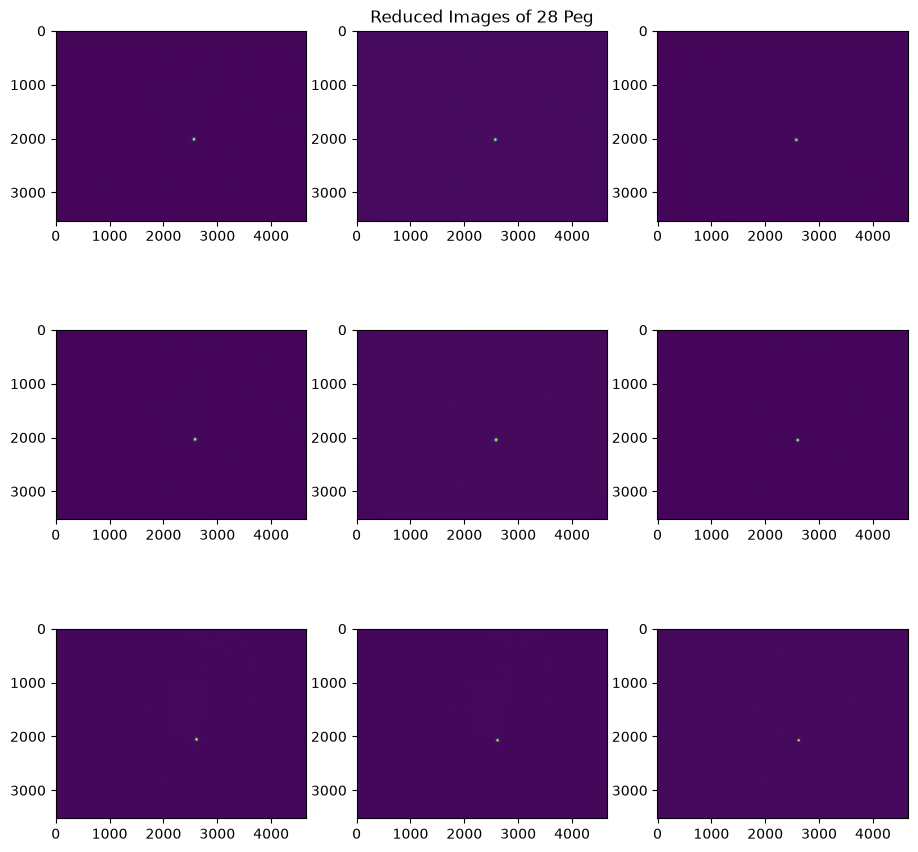

In [12]:
plt.figure(figsize=[11,11])
plt.subplot(331)
plt.imshow(Peg_28_data_reduced[0])
plt.subplot(332)
plt.title('Reduced Images of 28 Peg')
plt.imshow(Peg_28_data_reduced[1])
plt.subplot(333)
plt.imshow(Peg_28_data_reduced[2])
plt.subplot(334)
plt.imshow(Peg_28_data_reduced[3])
plt.subplot(335)
plt.imshow(Peg_28_data_reduced[4])
plt.subplot(336)
plt.imshow(Peg_28_data_reduced[5])
plt.subplot(337)
plt.imshow(Peg_28_data_reduced[6])
plt.subplot(338)
plt.imshow(Peg_28_data_reduced[7])
plt.subplot(339)
plt.imshow(Peg_28_data_reduced[8])
plt.savefig('Peg_28.png')

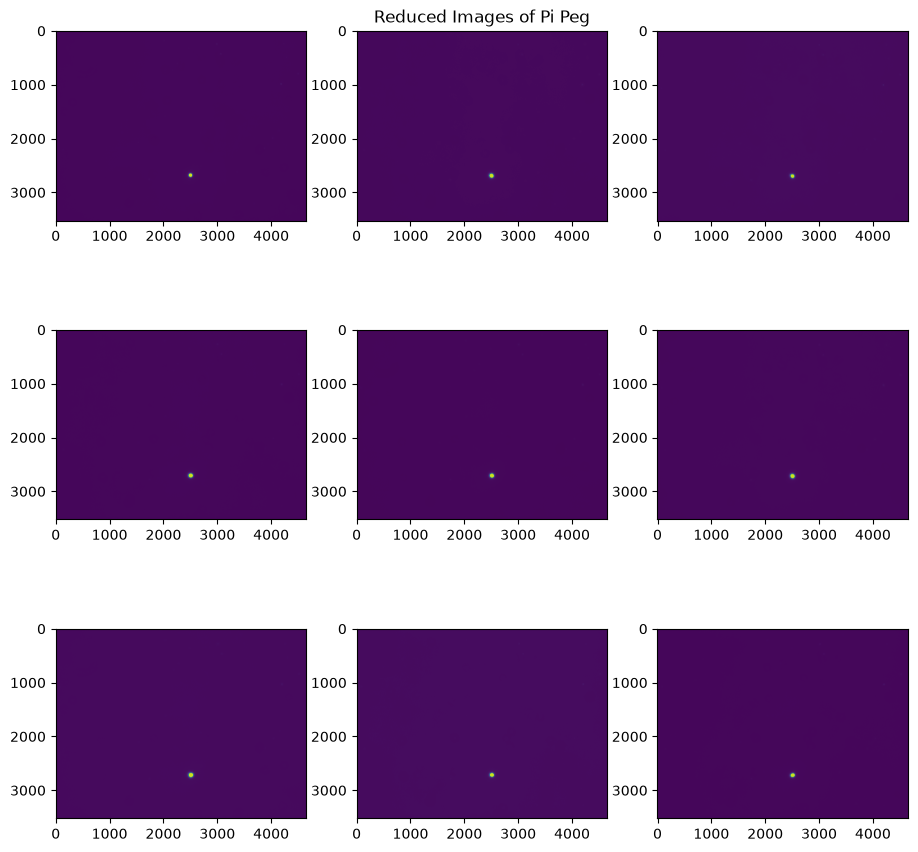

In [13]:
plt.figure(figsize=[11,11])
plt.subplot(331)
plt.imshow(Peg_pi_data_reduced[0])
plt.subplot(332)
plt.title('Reduced Images of Pi Peg')
plt.imshow(Peg_pi_data_reduced[1])
plt.subplot(333)
plt.imshow(Peg_pi_data_reduced[2])
plt.subplot(334)
plt.imshow(Peg_pi_data_reduced[3])
plt.subplot(335)
plt.imshow(Peg_pi_data_reduced[4])
plt.subplot(336)
plt.imshow(Peg_pi_data_reduced[5])
plt.subplot(337)
plt.imshow(Peg_pi_data_reduced[6])
plt.subplot(338)
plt.imshow(Peg_pi_data_reduced[7])
plt.subplot(339)
plt.imshow(Peg_pi_data_reduced[8])
plt.savefig('Peg_pi.png')

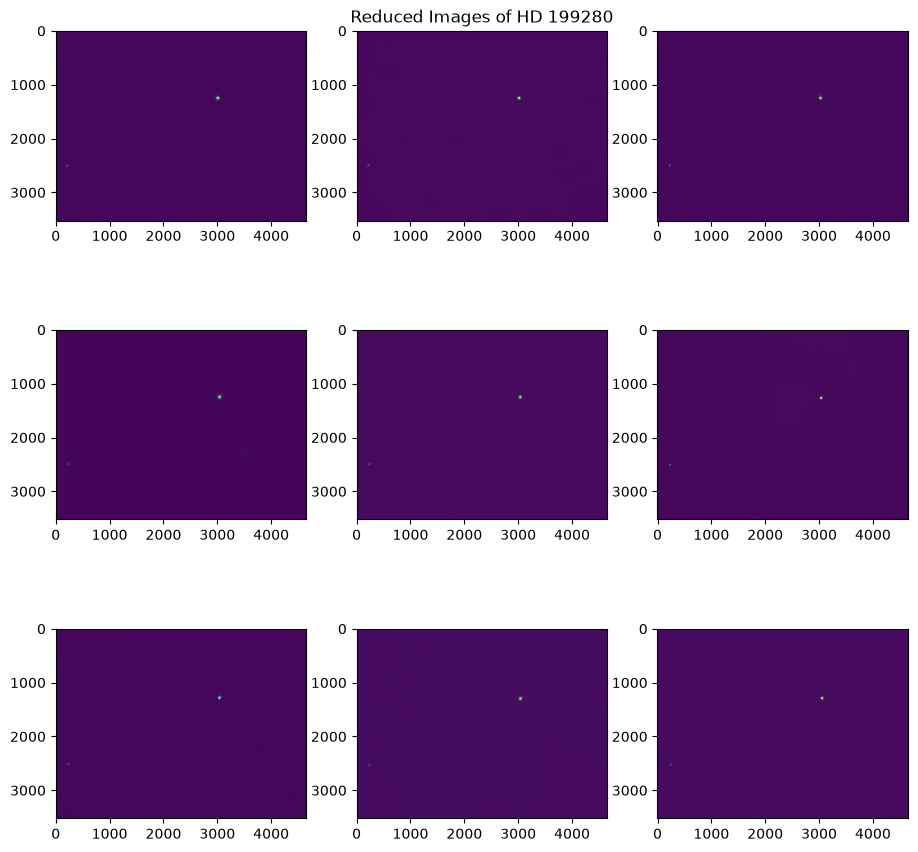

In [14]:
plt.figure(figsize=[11,11])
plt.subplot(331)
plt.imshow(HD_199280_data_reduced[0])
plt.subplot(332)
plt.title('Reduced Images of HD 199280')
plt.imshow(HD_199280_data_reduced[1])
plt.subplot(333)
plt.imshow(HD_199280_data_reduced[2])
plt.subplot(334)
plt.imshow(HD_199280_data_reduced[3])
plt.subplot(335)
plt.imshow(HD_199280_data_reduced[4])
plt.subplot(336)
plt.imshow(HD_199280_data_reduced[5])
plt.subplot(337)
plt.imshow(HD_199280_data_reduced[6])
plt.subplot(338)
plt.imshow(HD_199280_data_reduced[7])
plt.subplot(339)
plt.imshow(HD_199280_data_reduced[8])
plt.savefig('HD_199280.png')

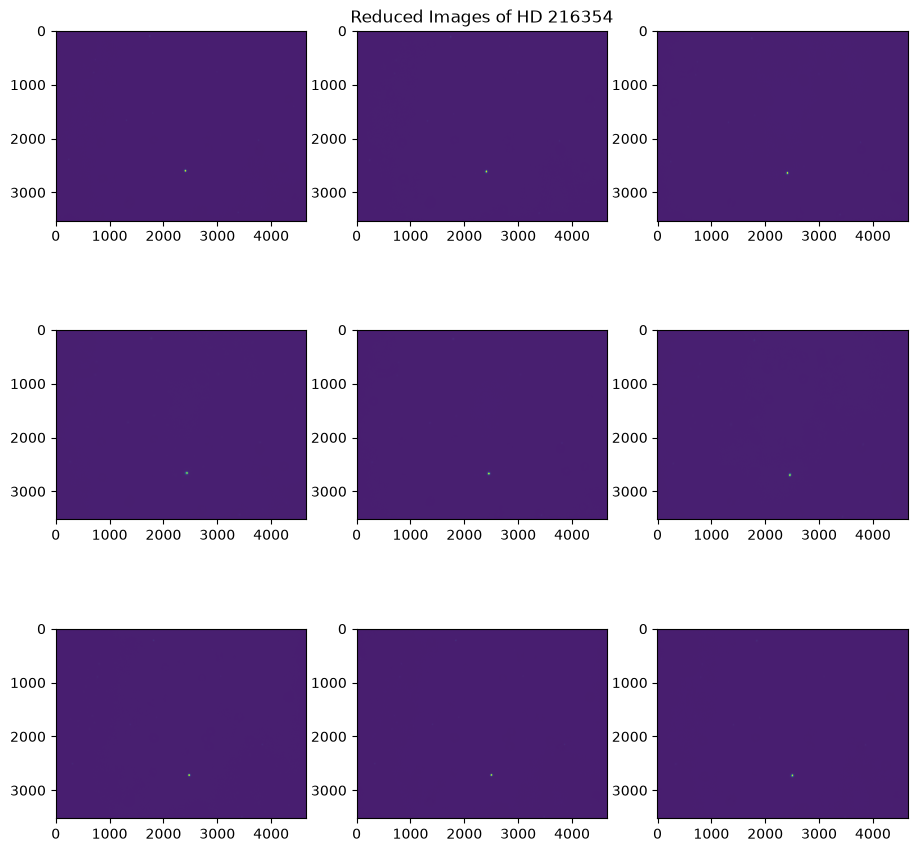

In [15]:
plt.figure(figsize=[11,11])
plt.subplot(331)
plt.imshow(HD_216354_data_reduced[0])
plt.subplot(332)
plt.title('Reduced Images of HD 216354')
plt.imshow(HD_216354_data_reduced[1])
plt.subplot(333)
plt.imshow(HD_216354_data_reduced[2])
plt.subplot(334)
plt.imshow(HD_216354_data_reduced[3])
plt.subplot(335)
plt.imshow(HD_216354_data_reduced[4])
plt.subplot(336)
plt.imshow(HD_216354_data_reduced[5])
plt.subplot(337)
plt.imshow(HD_216354_data_reduced[6])
plt.subplot(338)
plt.imshow(HD_216354_data_reduced[7])
plt.subplot(339)
plt.imshow(HD_216354_data_reduced[8])
plt.savefig('HD_216354.png')

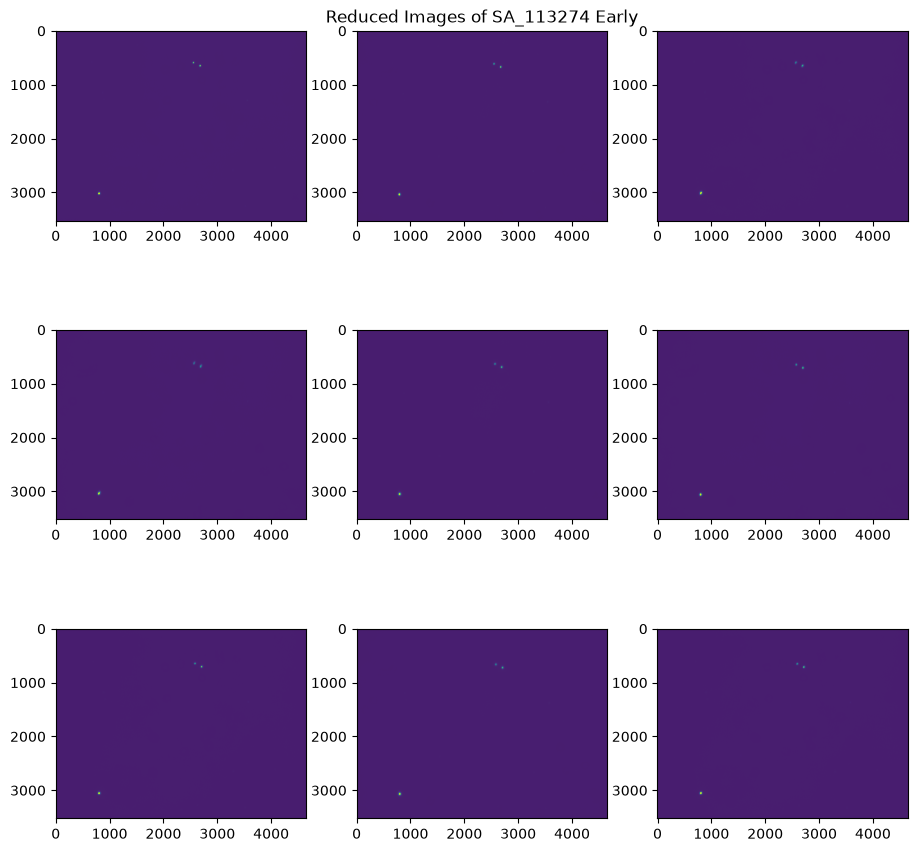

In [16]:
plt.figure(figsize=[11,11])
plt.subplot(331)
plt.imshow(SA_113274_1_data_reduced[0])
plt.subplot(332)
plt.title('Reduced Images of SA_113274 Early')
plt.imshow(SA_113274_1_data_reduced[1])
plt.subplot(333)
plt.imshow(SA_113274_1_data_reduced[2])
plt.subplot(334)
plt.imshow(SA_113274_1_data_reduced[3])
plt.subplot(335)
plt.imshow(SA_113274_1_data_reduced[4])
plt.subplot(336)
plt.imshow(SA_113274_1_data_reduced[5])
plt.subplot(337)
plt.imshow(SA_113274_1_data_reduced[6])
plt.subplot(338)
plt.imshow(SA_113274_1_data_reduced[7])
plt.subplot(339)
plt.imshow(SA_113274_1_data_reduced[8])
plt.savefig('SA_113274_Early.png')

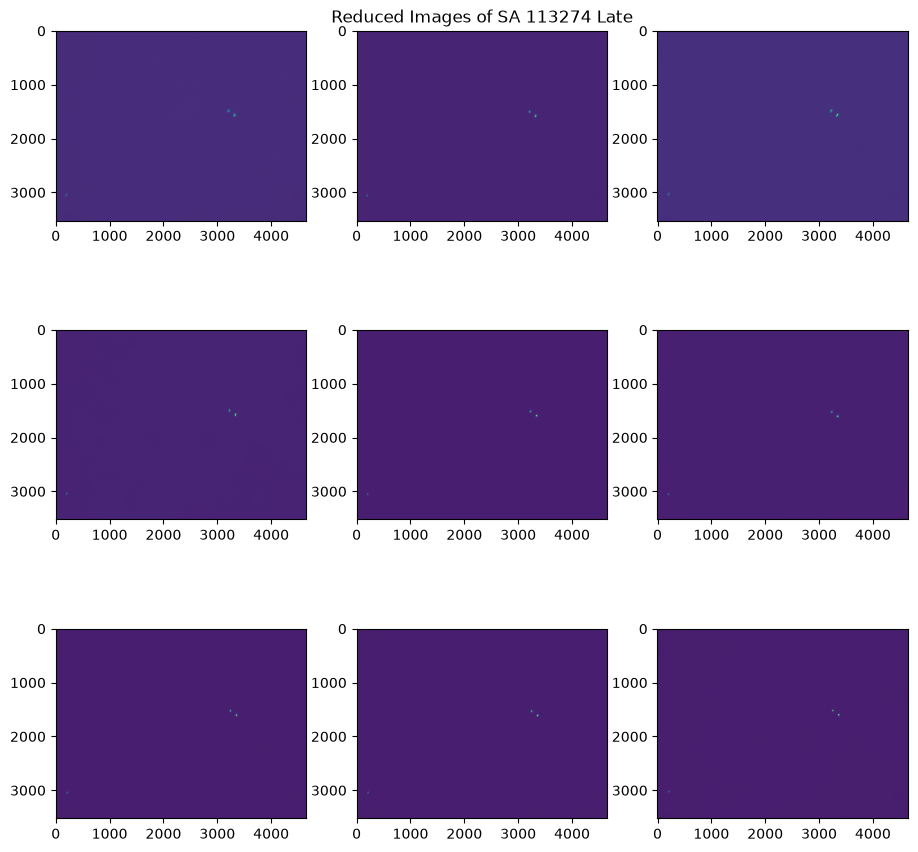

In [17]:
plt.figure(figsize=[11,11])
plt.subplot(331)
plt.imshow(SA_113274_2_data_reduced[0])
plt.subplot(332)
plt.title('Reduced Images of SA 113274 Late')
plt.imshow(SA_113274_2_data_reduced[1])
plt.subplot(333)
plt.imshow(SA_113274_2_data_reduced[2])
plt.subplot(334)
plt.imshow(SA_113274_2_data_reduced[3])
plt.subplot(335)
plt.imshow(SA_113274_2_data_reduced[4])
plt.subplot(336)
plt.imshow(SA_113274_2_data_reduced[5])
plt.subplot(337)
plt.imshow(SA_113274_2_data_reduced[6])
plt.subplot(338)
plt.imshow(SA_113274_2_data_reduced[7])
plt.subplot(339)
plt.imshow(SA_113274_2_data_reduced[8])
plt.savefig('SA_113274_Late.png')

In [51]:
representative_flats = np.array([twilights_data_corrected[0], twilights_data_corrected[1],
                        twilights_data_corrected[3], twilights_data_corrected[4],
                        twilights_data_corrected[6], twilights_data_corrected[7],
                        twilights_data_corrected[10], twilights_data_corrected[11],
                        twilights_data_corrected[15], twilights_data_corrected[16],
                        twilights_data_corrected[20], twilights_data_corrected[21], 
                        twilights_data_corrected[28], twilights_data_corrected[29],
                        twilights_data_corrected[35], twilights_data_corrected[36],
                        twilights_data_corrected[54], twilights_data_corrected[55],
                        twilights_data_corrected[98], twilights_data_corrected[99]
                       ])

In [52]:
representative_flats_reduced = [(image - bias_mean) for image in representative_flats]
representative_flats_reduced = np.array(representative_flats_reduced)

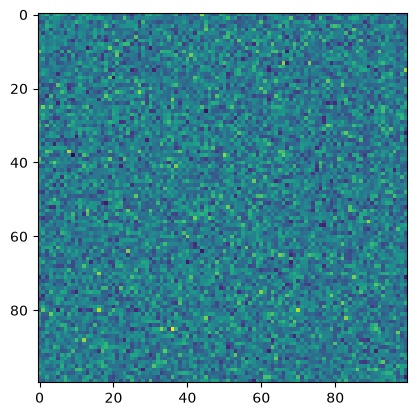

In [122]:
plt.imshow(representative_flats_reduced[19][1800:1900, 2200:2300])

In [53]:
f_a = []
f_b = []
for image in representative_flats_reduced[::2, :, :]:
    f_a.append(np.mean(image))
for image in representative_flats_reduced[1::2, :, :]:
    f_b.append(np.mean(image))

f_a, f_b = np.array(f_a), np.array(f_b)

In [54]:
ratios = f_a / f_b
representative_flats_reduced[1:20:2, :, :] *= ratios[:10, None, None]

In [55]:
difference_images = representative_flats_reduced[::2, :, :] - representative_flats_reduced[1::2, :, :]


In [56]:
diff_variance = []
for image in difference_images:
    diff_variance.append(np.std(image[1800:1900, 2200:2300])**2)
diff_variance = np.array(diff_variance)
a_variance = diff_variance *np.sqrt(2)
a_variance

array([8528.1164642 , 7705.67890283, 6847.83603544, 5920.03603192,
       4869.88021376, 4108.9052235 , 3045.47042535, 2136.10310446,
       1193.29871552,  280.86647967])

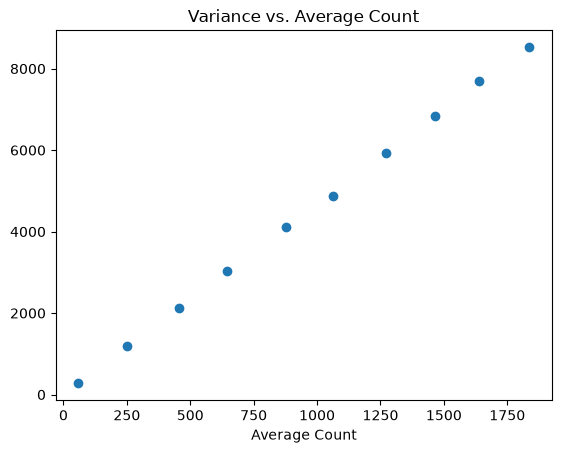

In [57]:
plt.scatter(f_a, a_variance)
plt.title("Variance vs. Average Count")
plt.xlabel('Average Count')
plt.savefig('Variance Vs. Average Count.png')

In [58]:
g, b, unc_y, chi_sqr, unc_g, unc_b = derryck.lin_least_square_weighted(f_a, a_variance, np.sqrt(f_a))
print(g, unc_g, chi_sqr/10)

13.946240984550741 7.2312524642342275 1.4369304000791645


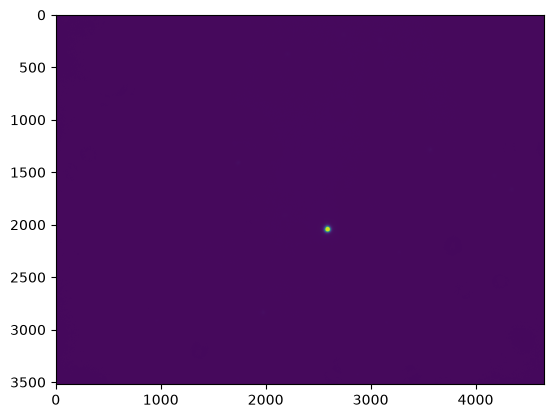

In [177]:
plt.imshow(Peg_28_data_reduced[4])

In [87]:
x_mean, y_mean = 2510, 2710
x_mean_blank, y_mean_blank = 2510, 1000
ranges = [50, 75, 100, 125, 150, 175, 200, 225, 250]

cutouts = []
blank_cutouts = []

for value in ranges:
    cutouts.append( Peg_pi_data_reduced[4][y_mean-value:y_mean+value, x_mean-value:x_mean+value])
    blank_cutouts.append( Peg_pi_data_reduced[4][y_mean_blank-value:y_mean_blank+value, x_mean_blank-value:x_mean_blank+value])

xvals0, yvals0 = np.meshgrid(np.arange(x_mean-ranges[0], x_mean+ranges[0]),np.arange(y_mean-ranges[0],y_mean+ranges[0]))
xvals1, yvals1 = np.meshgrid(np.arange(x_mean-ranges[1], x_mean+ranges[1]),np.arange(y_mean-ranges[1],y_mean+ranges[1]))
xvals2, yvals2 = np.meshgrid(np.arange(x_mean-ranges[2], x_mean+ranges[2]),np.arange(y_mean-ranges[2],y_mean+ranges[2]))
xvals3, yvals3 = np.meshgrid(np.arange(x_mean-ranges[3], x_mean+ranges[3]),np.arange(y_mean-ranges[3],y_mean+ranges[3]))
xvals4, yvals4 = np.meshgrid(np.arange(x_mean-ranges[4], x_mean+ranges[4]),np.arange(y_mean-ranges[4],y_mean+ranges[4]))
xvals5, yvals5 = np.meshgrid(np.arange(x_mean-ranges[5], x_mean+ranges[5]),np.arange(y_mean-ranges[5],y_mean+ranges[5]))
xvals6, yvals6 = np.meshgrid(np.arange(x_mean-ranges[6], x_mean+ranges[6]),np.arange(y_mean-ranges[6],y_mean+ranges[6]))
xvals7, yvals7 = np.meshgrid(np.arange(x_mean-ranges[7], x_mean+ranges[7]),np.arange(y_mean-ranges[7],y_mean+ranges[7]))
xvals8, yvals8 = np.meshgrid(np.arange(x_mean-ranges[8], x_mean+ranges[8]),np.arange(y_mean-ranges[8],y_mean+ranges[8]))
xvals = [xvals0, xvals1, xvals2, xvals3, xvals4, xvals5, xvals6, xvals7, xvals8]
yvals = [yvals0, yvals1, yvals2, yvals3, yvals4, yvals5, yvals6, yvals7, yvals8]

x_stddev, y_stddev = 30, 30

In [118]:
convolves, fluxes, blank_convolves, psfs = [], [], [], []
for i in range(len(xvals)):
    psf, psf_convolve, psf_flux = derryck.photometry(xvals[i], yvals[i], x_mean, y_mean, x_stddev, y_stddev, cutouts[i])
    blank_psf, blank_convolve, blank_flux = derryck.photometry(xvals[i], yvals[i], x_mean, y_mean, x_stddev, y_stddev, blank_cutouts[i])
    
    convolves.append(psf_convolve)
    fluxes.append(psf_flux)
    blank_convolves.append(blank_convolve)
    psfs.append(psf)
    
convolves =  np.array(convolves, dtype=object)
fluxes = np.array(fluxes, dtype=object)
blank_convolves =  np.array(blank_convolves, dtype=object)

In [119]:
sky_counts = []
for i in range(len(blank_convolves)):
    sky_count = np.median(blank_convolves[i])
    sky_counts.append(sky_count)

In [149]:
pixel_counts = []
for i in range(len(fluxes)):
    fluxes[i] += sky_counts[i] * np.size(convolves[i])
    pixel_counts.append(np.size(convolves[i]))

In [186]:
def get_SNR(star_counts, gain, sky_counts, num_pix, read_noise):
    star_counts = np.array(star_counts)
    sky_counts = np.array(sky_counts)
    SNR = star_counts / (np.sqrt(
        gain * star_counts + gain * sky_counts * num_pix + num_pix * read_noise**2
    ))
    return SNR
    
def get_inst_mag(x_mean, y_mean, x_stddev, y_stddev, cutout, blank_cutout, ranges):

    x, y = np.meshgrid(np.arange(x_mean-ranges, x_mean+ranges),np.arange(y_mean-ranges,y_mean+ranges))
    
    psf, psf_convolve, psf_flux = derryck.photometry(x, y, x_mean, y_mean, x_stddev, y_stddev, cutout)
    blank_psf, blank_convolve, blank_flux = derryck.photometry(x, y, x_mean, y_mean, x_stddev, y_stddev, blank_cutout)
    
    sky_count = np.median(blank_convolve)
    pixel_count = np.size(psf_convolve)
    psf_flux += sky_count * pixel_count
    
    inst_mag = -2.5 * np.log10(psf_flux/10)
    SNR = get_SNR(psf_flux, g, sky_count, pixel_count, read_noise)
    inst_mag_unc = np.abs(inst_mag/SNR)

    return inst_mag, inst_mag_unc, SNR

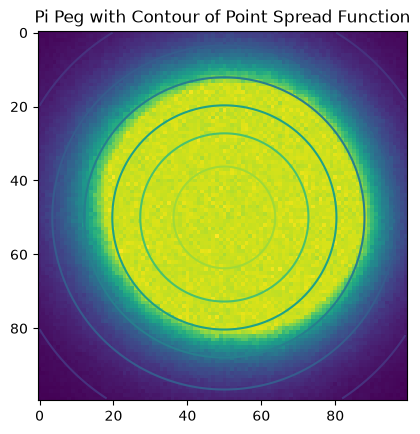

In [122]:
plt.imshow(cutouts[0])
plt.contour(psfs[0])
plt.title("Pi Peg with Contour of Point Spread Function")
plt.savefig('pi_peg_psf_contour.png')

In [180]:
SNRs = []
for i in range(len(fluxes)):
    SNRs.append(get_SNR(fluxes[i], g, sky_counts[i], pixel_counts[i], read_noise))

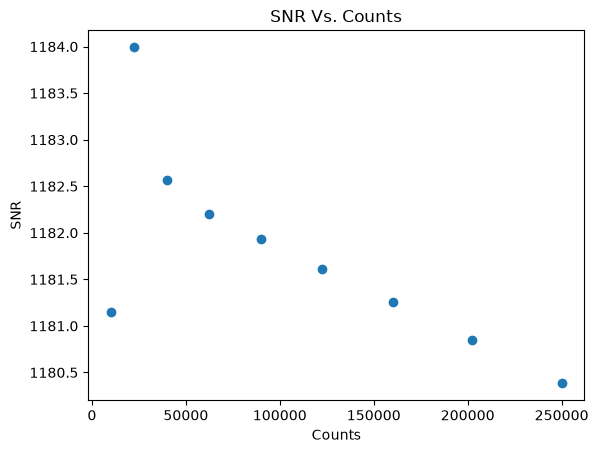

In [176]:
plt.scatter(pixel_counts, SNRs)
plt.title('SNR Vs. Counts')
plt.xlabel('Counts')
plt.ylabel('SNR')
plt.savefig('SNR_vs_counts.png')

In [178]:
xvals_ideal, yvals_ideal = xvals[1], yvals[1]
psf_ideal, range_ideal = psf[1], ranges[1]
flux_ideal_pi_peg, SNR_ideal_pi_peg = fluxes[1], SNRs[1]
pixel_count_ideal = pixel_counts[1]

In [173]:
inst_mag_pi_peg = -2.5 * np.log10(flux_ideal_pi_peg/10)
inst_mag_unc_pi_peg = np.abs(inst_mag_pi_peg/SNR_ideal_pi_peg)
print(inst_mag_pi_peg, inst_mag_unc_pi_peg)

-15.689127449159121 0.013251018665468833


In [204]:
x_mean_peg_28, y_mean_peg_28 = 2590, 2050
x_mean_HD216354, y_mean_HD216354 = 2455, 2670
x_mean_HD199280, y_mean_HD199280 = 3040, 1250
x_mean_SA113274E_1, y_mean_SA113274E_1 = 2570, 635
x_mean_SA113274E_2, y_mean_SA113274E_2 = 2690, 690
x_mean_SA113274L_1, y_mean_SA113274L_1 = 3230, 1520
x_mean_SA113274L_2, y_mean_SA113274L_2 = 3355, 1605

peg_28_cutout = Peg_28_data_reduced[4][y_mean_peg_28-range_ideal:y_mean_peg_28+range_ideal, 
    x_mean_peg_28-range_ideal:x_mean_peg_28+range_ideal]

HD_216354_cutout = HD_216354_data_reduced[4][y_mean_HD216354-range_ideal:y_mean_HD216354+range_ideal, 
    x_mean_HD216354-range_ideal:x_mean_HD216354+range_ideal]

HD_199280_cutout = HD_199280_data_reduced[4][y_mean_HD199280-range_ideal:y_mean_HD199280+range_ideal, 
    x_mean_HD199280-range_ideal:x_mean_HD199280+range_ideal]

SA_113274E_1_cutout = SA_113274_1_data_reduced[4][y_mean_SA113274E_1-range_ideal:y_mean_SA113274E_1+range_ideal, 
    x_mean_SA113274E_1-range_ideal:x_mean_SA113274E_1+range_ideal]

SA_113274E_2_cutout = SA_113274_1_data_reduced[4][y_mean_SA113274E_2-range_ideal:y_mean_SA113274E_2+range_ideal, 
    x_mean_SA113274E_2-range_ideal:x_mean_SA113274E_2+range_ideal]

SA_113274L_1_cutout = SA_113274_2_data_reduced[4][y_mean_SA113274L_1-range_ideal:y_mean_SA113274L_1+range_ideal, 
    x_mean_SA113274L_1-range_ideal:x_mean_SA113274L_1+range_ideal]

SA_113274L_2_cutout = SA_113274_2_data_reduced[6][y_mean_SA113274L_2-range_ideal:y_mean_SA113274L_2+range_ideal, 
    x_mean_SA113274L_2-range_ideal:x_mean_SA113274L_2+range_ideal]


blank_y_mean = 3000
blank_x_mean = 1900

peg_28_blank = Peg_28_data_reduced[4][blank_y_mean-range_ideal:blank_y_mean+range_ideal, 
    blank_x_mean-range_ideal:blank_x_mean+range_ideal]

HD_216354_blank = HD_216354_data_reduced[4][blank_y_mean-range_ideal:blank_y_mean+range_ideal, 
    blank_x_mean-range_ideal:blank_x_mean+range_ideal]

HD_199280_blank = HD_199280_data_reduced[4][blank_y_mean-range_ideal:blank_y_mean+range_ideal, 
    blank_x_mean-range_ideal:blank_x_mean+range_ideal]

SA_113274E_1_blank = SA_113274_1_data_reduced[4][blank_y_mean-range_ideal:blank_y_mean+range_ideal, 
    blank_x_mean-range_ideal:blank_x_mean+range_ideal]

SA_113274E_2_blank = SA_113274_1_data_reduced[4][blank_y_mean-range_ideal:blank_y_mean+range_ideal, 
    blank_x_mean-range_ideal:blank_x_mean+range_ideal]

SA_113274L_1_blank = SA_113274_2_data_reduced[4][blank_y_mean-range_ideal:blank_y_mean+range_ideal, 
    blank_x_mean-range_ideal:blank_x_mean+range_ideal]

SA_113274L_2_blank = SA_113274_2_data_reduced[6][blank_y_mean-range_ideal:blank_y_mean+range_ideal, 
    blank_x_mean-range_ideal:blank_x_mean+range_ideal]

In [192]:
inst_mag_peg_28, inst_mag_peg_28_unc, peg_28_SNR = get_inst_mag(x_mean_peg_28, y_mean_peg_28, x_stddev, y_stddev, peg_28_cutout, peg_28_blank, range_ideal)
print(inst_mag_peg_28, inst_mag_peg_28_unc, peg_28_SNR)

-14.958105886052893 0.01736369780391309 861.4585473079316


In [194]:
inst_mag_HD_216354, inst_mag_HD_216354_unc, HD_216354_SNR = get_inst_mag(x_mean_HD216354, y_mean_HD216354, x_stddev, y_stddev, HD_216354_cutout, HD_216354_blank, range_ideal)
print(inst_mag_HD_216354, inst_mag_HD_216354_unc, HD_216354_SNR)

-14.206974961477552 0.02256418425762473 629.6250198664652


In [195]:
inst_mag_HD_199280, inst_mag_HD_199280_unc, HD_199280_SNR = get_inst_mag(x_mean_HD199280, y_mean_HD199280, x_stddev, y_stddev, HD_199280_cutout, HD_199280_blank, range_ideal)
print(inst_mag_HD_199280, inst_mag_HD_199280_unc, HD_199280_SNR)

-14.866246210733795 0.017939499719108704 828.6878922770986


In [197]:
inst_mag_SA_113274E_1, inst_mag_SA_113274E_1_unc, SA_113274E_1_SNR = get_inst_mag(x_mean_SA113274E_1, y_mean_SA113274E_1, x_stddev, y_stddev, SA_113274E_1_cutout, SA_113274E_1_blank, range_ideal)
print(inst_mag_SA_113274E_1, inst_mag_SA_113274E_1_unc, SA_113274E_1_SNR)

-12.206773253365707 0.022276216912370618 547.9733520904502


In [198]:
inst_mag_SA_113274E_2, inst_mag_SA_113274E_2_unc, SA_113274E_2_SNR = get_inst_mag(x_mean_SA113274E_2, y_mean_SA113274E_2, x_stddev, y_stddev, SA_113274E_2_cutout, SA_113274E_2_blank, range_ideal)
print(inst_mag_SA_113274E_2, inst_mag_SA_113274E_2_unc, SA_113274E_2_SNR)

-13.206184595935843 0.02925431307689165 451.4269250221286


In [200]:
inst_mag_SA_113274L_1, inst_mag_SA_113274L_1_unc, SA_113274L_1_SNR = get_inst_mag(x_mean_SA113274L_1, y_mean_SA113274L_1, x_stddev, y_stddev, SA_113274L_1_cutout, SA_113274L_1_blank, range_ideal)
print(inst_mag_SA_113274L_1, inst_mag_SA_113274L_1_unc, SA_113274L_1_SNR)

-12.332967608818205 0.024033623244804 513.1547367284521


In [205]:
inst_mag_SA_113274L_2, inst_mag_SA_113274L_2_unc, SA_113274L_2_SNR = get_inst_mag(x_mean_SA113274L_2, y_mean_SA113274L_2, x_stddev, y_stddev, SA_113274L_2_cutout, SA_113274L_2_blank, range_ideal)
print(inst_mag_SA_113274L_2, inst_mag_SA_113274L_2_unc, SA_113274L_2_SNR)

-13.337193113478268 0.028283841819269077 471.5481439438673


In [223]:
pi_peg_X = np.cos(np.deg2rad(90 - (64 + 25/60 + 59.5/3600))) ** -1
peg_28_X = np.cos(np.deg2rad(90 - (55 + 9/60 + 18.2/3600)))** -1
HD216354_X = np.cos(np.deg2rad(90 - (63 + 4/60 + 59.2/3600)))** -1
HD199280_X = np.cos(np.deg2rad(90 - (39 + 29/60 + 6.4/3600)))** -1
SA113274E_X = np.cos(np.deg2rad(90 - (39 + 9/60 + 35.3/3600)))** -1
SA113274L_X = np.cos(np.deg2rad(90 - (42 + 32/60 + 17.4/3600)))** -1

print(HD199280_X, SA113274E_X, SA113274L_X)

Xs = [HD199280_X, SA113274E_X, SA113274E_X, SA113274L_X, SA113274L_X]

1.5726294924832924 1.5835676254637618 1.479112309093933


In [221]:
HD199280_m = 6.566
SA_113274_m = 8.831


HD199280_C = HD199280_m - inst_mag_HD_199280
SA113274E_1_C = SA_113274_m - inst_mag_SA_113274E_1
SA113274E_2_C = SA_113274_m - inst_mag_SA_113274E_2
SA113274L_1_C = SA_113274_m - inst_mag_SA_113274L_1
SA113274L_2_C = SA_113274_m - inst_mag_SA_113274L_2
Cs = [HD199280_C, SA113274E_1_C,SA113274E_2_C, SA113274L_1_C,SA113274L_2_C]
print(Cs)

[np.float64(21.432246210733794), np.float64(21.037773253365707), np.float64(22.03718459593584), np.float64(21.163967608818204), np.float64(22.168193113478267)]


In [225]:
k, zp, unc_c, chi_sqr, unc_k, unc_zp = derryck.lin_least_square(Xs, Cs)


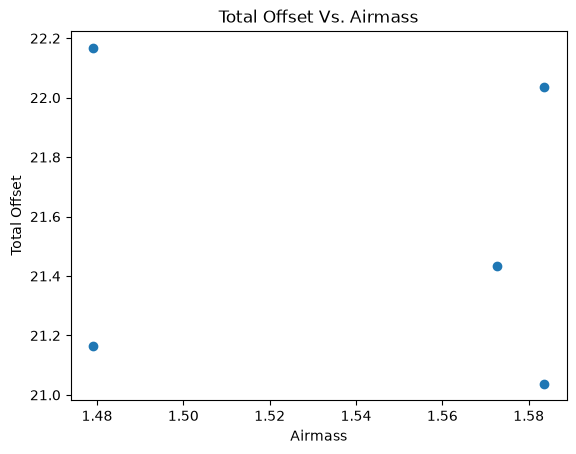

In [230]:
plt.scatter(Xs, Cs)
plt.title('Total Offset Vs. Airmass')
plt.xlabel('Airmass')
plt.ylabel('Total Offset')
plt.savefig('offset_vs_airmass.png')


In [226]:
print(k, unc_k, zp, unc_zp, unc_c, chi_sqr)

23.95514890983367 8.08187227880385 -1.550584081913361 5.246623500744651 0.5812816796641341 3.0000000000000004


In [231]:
pi_peg_mag = inst_mag_pi_peg + zp + k*pi_peg_X
peg_28_mag = inst_mag_peg_28 + zp + k*peg_28_X
HD_216354_mag = inst_mag_HD_216354 + zp + k*HD199280_X

In [232]:
print(pi_peg_mag, peg_28_mag, HD_216354_mag)

9.315668345721377 12.679943840161037 21.91501462904251


In [233]:
def get_error(unc_zp, X, unc_k):
    unc_c = np.sqrt ( unc_zp**2 + (X * unc_k) **2 )
    return unc_c

In [237]:
pi_peg_mag_unc = get_error(unc_zp, pi_peg_X, unc_k)
peg_28_mag_unc = get_error(unc_zp, peg_28_X, unc_k)
HD_216354_mag_unc = get_error(unc_zp, HD216354_X, unc_k)

In [238]:
print(pi_peg_mag, pi_peg_mag_unc, peg_28_mag, peg_28_mag_unc, HD_216354_mag, HD_216354_mag_unc)

9.315668345721377 10.38234030197308 12.679943840161037 11.157988632051254 21.91501462904251 10.47280621285085


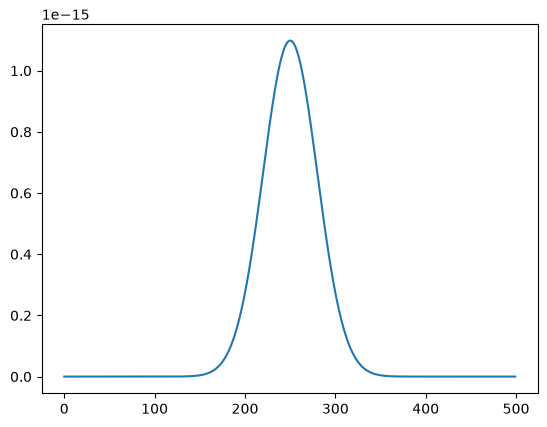

In [243]:
plt.plot(psf_ideal)